# Cross-domain cold-start recommendation: Books → Movies & TV

**From a reproduced DUPGT-CDR baseline, through semantic and LLM extensions, to what happens when few users are shared between domains.**

A *cold-start* user has rated Books but no Movies. The task is to predict the star rating (1–5) they would give a Movie, using only their Book history and what the model learned from users active in both domains.

### The story in six points
1. **The baseline reproduces.** DUPGT-CDR beats every simple baseline on both Amazon releases (2014 and 2023), cutting RMSE by about 3–4% against predicting each movie's average rating.
2. **An LLM as a teacher does not help.** Two different designs were tested: pairwise preferences, and generated interests used to retrieve movies. Both are indistinguishable from controls that contain no personal information.
3. **Text semantics help a little, reliably.** A gate that reads Book and Movie descriptions lowers RMSE by about 0.004, consistently across seeds.
4. **Too few shared users makes transfer harmful.** With 1% of shared users, every transfer model is worse than the movie average. Transfer only pays off somewhere between 1% and 10%.
5. **Average gains hide many harmed users.** Even with all shared users, about 4 in 10 test users are worse off with transfer. At low overlap, DUPGT's high/low gate collapses onto a single branch.
6. **Knowing when not to transfer fixes low overlap.** Falling back to the movie average where the bridge is uncertain (inverse-variance weighting) makes transfer beat the movie average even at 1% overlap. At 10%, it beats DUPGT trained on all shared users. Most of the gain comes from shrinkage. Uncertainty adds a small but consistent extra.

In [1]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from summarise_overlap_seeds import collect, summarise

OUT = ROOT / "outputs"
FIGURES = OUT / "amazon2023/presentation_figures"
FIGURES.mkdir(parents=True, exist_ok=True)
read = lambda path: json.loads(Path(path).read_text())

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
GREY, BLACK, BLUE, ORANGE, GREEN, PURPLE, GOLD = "#8a8a8a", "#222222", "#2b6cb0", "#c05621", "#2f855a", "#805ad5", "#b7791f"
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=180, bbox_inches="tight")
def fmt(frame, digits=4, **extra):
    numbers = {c: f"{{:.{digits}f}}" for c in frame.select_dtypes("float").columns}
    return frame.style.format({**numbers, **extra}).hide(axis="index")

## 1. Task and evaluation protocol

| | |
|---|---|
| **Source domain** | Books (ratings and catalogue text) |
| **Target domain** | Movies & TV |
| **Test users** | Shared users held out entirely: their Movie ratings are hidden and used only for scoring (*user-disjoint cold start*) |
| **Metrics** | MAE (average error in stars) and RMSE (penalises large misses). Lower is better |
| **Model selection** | Every model's checkpoint is chosen by **validation** RMSE. Final comparisons were locked before test scores were read |

**Baselines**
* **Global mean:** one average rating for everything.
* **Movie average:** each movie's training-set average. This is the *target-only* reference: it uses no transfer at all.
* **Linear mapping:** a single learned map from a user's Book vector to a Movie vector.
* **DUPGT-CDR:** separate *high* (4–5★) and *low* (1–3★) Book histories, each turned into a personalised bridge by a meta-network, then mixed by a learned gate α_high for each user–movie pair.

## 2. Data

Two releases of the public Amazon Reviews 5-core data were used: 2014, to reproduce the original paper, and 2023, the larger and newer release used for all extensions.

In [2]:
rows = []
for year in ("2014", "2023"):
    m = read(OUT / f"amazon{year}/full_seed2020/dataset_manifest.json")
    s = m["splits"]
    rows.append({"Release": year, "Shared users": m["cohort"]["shared_users"],
                 "Book ratings": s["source_train"]["ratings"], "Movie training ratings": s["target_train"]["ratings"],
                 "Bridge-training users": s["meta_train"]["users"], "Validation users": s["validation"]["users"],
                 "Test users": s["test"]["users"], "Test ratings": s["test"]["ratings"]})
data_table = pd.DataFrame(rows)
display(data_table.style.format({c: "{:,}" for c in data_table.columns if c != "Release"}).hide(axis="index"))

Release,Shared users,Book ratings,Movie training ratings,Bridge-training users,Validation users,Test users,Test ratings
2014,"37,388","8,898,041","1,446,273","26,171","3,739","7,478","163,789"
2023,"127,188","9,488,297","6,797,056","89,031","12,719","25,438","433,618"


For the semantic extensions, Book and Movie catalogue descriptions were cleaned. HTML, biographies, sales text and format-only descriptions were removed, and missing descriptions were never invented. Coverage on 2023 is far better, which is one reason the extensions use 2023.

In [3]:
rows = []
for year in ("2014", "2023"):
    m = read(ROOT / f"data/metadata/amazon{year}/clean/metadata_manifest.json")
    p = m["coverage"]["populations"]["source_only_training"]
    rows.append({"Release": year, "Warm movies with usable text": m["coverage"]["warm_movies_with_content"],
                 "Source-only users": p["users"], "…with ≥3 described Books": p["eligible_at_minimum"],
                 "Share eligible": p["eligible_at_minimum"] / p["users"]})
coverage = pd.DataFrame(rows)
display(coverage.style.format({"Warm movies with usable text": "{:,}", "Source-only users": "{:,}",
                               "…with ≥3 described Books": "{:,}", "Share eligible": "{:.1%}"}).hide(axis="index"))

Release,Warm movies with usable text,Source-only users,…with ≥3 described Books,Share eligible
2014,"23,188","566,280","76,015",13.4%
2023,"96,969","649,182","648,443",99.9%


## 3. Reproducing the DUPGT-CDR baseline

Each release is trained in the same way. First, Book and Movie factor models are learned separately. Then the linear mapping and the DUPGT bridge are trained on the shared training users.

Release,RMSE reduction vs movie average,MAE reduction vs movie average,Users worse off than movie average,Mean gate weight on the high branch
2014,3.1%,4.7%,46%,0.37
2023,3.7%,5.1%,42%,0.88


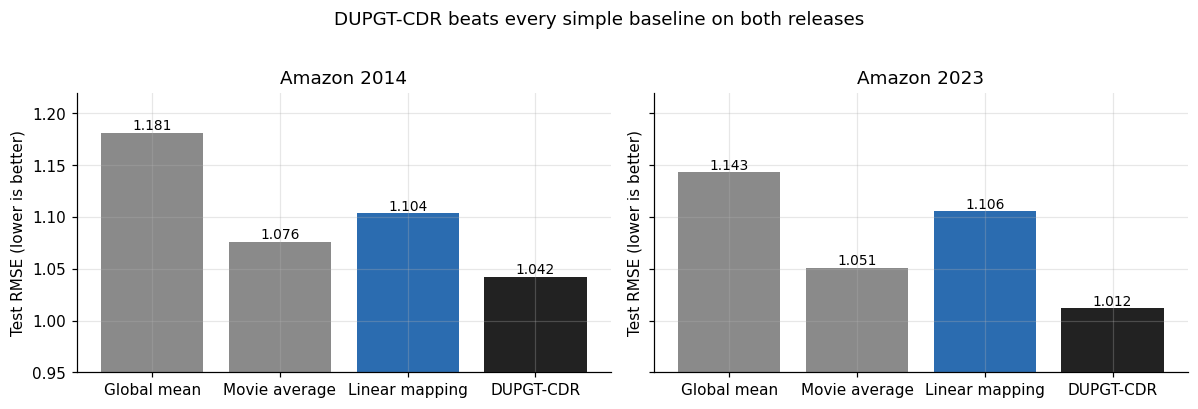

In [4]:
names = {"global_mean": "Global mean", "movie_mean": "Movie average", "linear_mapping": "Linear mapping", "dupgt": "DUPGT-CDR"}
rows, harm = [], []
for year in ("2014", "2023"):
    m = read(OUT / f"amazon{year}/full_seed2020/metrics.json")
    for key, name in names.items():
        rows.append({"Release": year, "Model": name, "MAE": m["results"][key]["raw"]["mae"], "RMSE": m["results"][key]["raw"]["rmse"]})
    base, model = m["results"]["movie_mean"]["raw"], m["results"]["dupgt"]["raw"]
    harm.append({"Release": year, "RMSE reduction vs movie average": (base["rmse"] - model["rmse"]) / base["rmse"],
                 "MAE reduction vs movie average": (base["mae"] - model["mae"]) / base["mae"],
                 "Users worse off than movie average": m["user_level_comparison"]["dupgt"]["fraction_harmed"],
                 "Mean gate weight on the high branch": m["gate_summary"]["mean_high_weight"]})
baseline = pd.DataFrame(rows)
display(baseline.pivot(index="Model", columns="Release", values=["RMSE", "MAE"]).loc[list(names.values())].style.format("{:.4f}"))
display(pd.DataFrame(harm).style.format({"RMSE reduction vs movie average": "{:.1%}", "MAE reduction vs movie average": "{:.1%}",
        "Users worse off than movie average": "{:.0%}", "Mean gate weight on the high branch": "{:.2f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for axis, year in zip(axes, ("2014", "2023")):
    part = baseline[baseline.Release == year]
    bars = axis.bar(part.Model, part.RMSE, color=[GREY, GREY, BLUE, BLACK])
    axis.bar_label(bars, fmt="%.3f", fontsize=9)
    axis.set(title=f"Amazon {year}", ylim=(0.95, 1.22), ylabel="Test RMSE (lower is better)")
fig.suptitle("DUPGT-CDR beats every simple baseline on both releases", y=1.02)
fig.tight_layout(); save(fig, "p01_baseline_reproduction"); plt.show()

**What this shows**
* DUPGT-CDR is the best model on both releases: about **3.1% (2014) and 3.7% (2023) lower RMSE** than the movie average. The simpler linear mapping is *worse* than the movie average, so the gains come from DUPGT's personalised bridges.
* The gain is real but modest, and it is an *average*. About **46% (2014) and 42% (2023) of test users** get a higher error with DUPGT than with the movie average. This *negative transfer* becomes a central theme later.
* The gate behaves very differently across releases. It leans on the low-rating branch in 2014 (mean α_high ≈ 0.37) and on the high-rating branch in 2023 (≈ 0.88).

## 4. First extension: an LLM as a pairwise teacher

**Idea.** DUPGT learns its bridge only from shared users. Many more users have Book ratings but no Movie ratings (*source-only* users). A local LLM (Qwen3.5-9B, not fine-tuned) reads 3–6 of their rated Books plus a short list of real Movie listings, and states which Movie in a pair the user would prefer. These weak preferences are added to training as a small auxiliary loss:

$$L = \text{MSE}_{\text{real ratings}} + \lambda\,\text{softplus}\big(-(\hat r_A - \hat r_B)\big)\qquad (A \text{ preferred over } B)$$

**Controls.** A *text* teacher makes the same choices from TF-IDF similarity, with no LLM. A *shuffled* teacher gives each user another user's LLM preferences, which keeps the label budget but removes any personal signal.

### How accurate is the teacher?
Before training, each teacher was checked on 20 validation users whose real Movie ratings are known. The question: does it pick the movie the user actually rated higher?

Teacher,Pairs answered,Correct,Accuracy
"LLM, shuffled profiles",49,19,39%
LLM (Qwen3.5-9B),52,24,46%
TF-IDF text similarity,52,29,56%
Movie popularity,51,32,63%


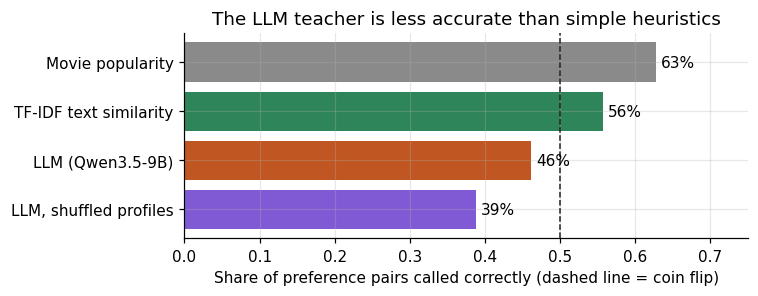

In [5]:
audit = read(OUT / "amazon2023/llm_transfer/teacher_audit_prompt_v2/comparison.json")
labels = {("dupgt-qwen35-9b", "original"): "LLM (Qwen3.5-9B)", ("dupgt-qwen35-9b", "shuffled"): "LLM, shuffled profiles",
          ("tfidf_text", "original"): "TF-IDF text similarity", ("training_popularity", "original"): "Movie popularity"}
acc = pd.DataFrame([{"Teacher": labels[(r["model"], r["profile"])], "Pairs answered": r["answered_pairs"],
                     "Correct": r["correct_pairs"], "Accuracy": r["accuracy_when_answered"]} for r in audit["results"]])
acc = acc.sort_values("Accuracy")
display(acc.style.format({"Accuracy": "{:.0%}"}).hide(axis="index"))
fig, axis = plt.subplots(figsize=(7, 2.8))
bars = axis.barh(acc.Teacher, acc.Accuracy, color=[PURPLE, ORANGE, GREEN, GREY])
axis.bar_label(bars, labels=[f"{v:.0%}" for v in acc.Accuracy], padding=3)
axis.axvline(0.5, color=BLACK, linestyle="--", linewidth=1)
axis.set(xlim=(0, 0.75), xlabel="Share of preference pairs called correctly (dashed line = coin flip)",
         title="The LLM teacher is less accurate than simple heuristics")
fig.tight_layout(); save(fig, "p02_teacher_audit"); plt.show()

### Does it improve the model?
Matched comparison at the selected weight λ = 0.01. All runs share the same users, the same starting bridge and the same test rows. The bridge was trained on 1% and on 10% of shared users.

In [6]:
plan = read(OUT / "amazon2023/llm_transfer/validation_grid_v2_seed2020/final_evaluation_plan.json")
teacher_names = {"none": "DUPGT (no teacher)", "llm": "+ LLM teacher", "text": "+ text teacher", "shuffled": "+ shuffled teacher"}
rows = []
for group in plan["groups"]:
    base = read(Path(group["matched_runs"][0]) / "test_metrics.json")["raw"]
    for directory in group["matched_runs"]:
        e, t = read(Path(directory) / "experiment.json"), read(Path(directory) / "test_metrics.json")
        rows.append({"Shared users used": f"{group['overlap_fraction']:.0%}", "Model": teacher_names[e["teacher_kind"]],
                     "MAE": t["raw"]["mae"], "RMSE": t["raw"]["rmse"], "ΔRMSE vs no teacher": t["raw"]["rmse"] - base["rmse"],
                     "Movie average RMSE": t["movie_mean"]["rmse"]})
pilot = pd.DataFrame(rows)
display(pilot.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "ΔRMSE vs no teacher": "{:+.4f}", "Movie average RMSE": "{:.4f}"}).hide(axis="index"))

Shared users used,Model,MAE,RMSE,ΔRMSE vs no teacher,Movie average RMSE
1%,DUPGT (no teacher),0.8131,1.1112,+0.0000,1.0507
1%,+ text teacher,0.8129,1.1107,-0.0006,1.0507
1%,+ LLM teacher,0.8128,1.1106,-0.0006,1.0507
1%,+ shuffled teacher,0.8128,1.1106,-0.0006,1.0507
10%,DUPGT (no teacher),0.7505,1.0310,+0.0000,1.0507
10%,+ text teacher,0.7477,1.0304,-0.0005,1.0507
10%,+ LLM teacher,0.7511,1.0307,-0.0002,1.0507
10%,+ shuffled teacher,0.7510,1.0307,-0.0002,1.0507


**What this shows**
* Every teacher moves RMSE by less than 0.001, and the **shuffled teacher does exactly as well as the real LLM teacher**. Whatever the auxiliary loss contributes, it is not personal information about the user.
* The audit explains why. The LLM calls only **46%** of preference pairs correctly, below a coin flip, TF-IDF text (56%) and plain popularity (63%).
* A side observation that shapes the rest of the project: with 1% of shared users, every model is *worse* than the movie average (RMSE ≈ 1.11 vs 1.051).

## 5. Second extension: semantic gate and a retrieval teacher

The pilot suggested that the model never sees *what* Books and Movies are about. DUPGT works only with item IDs. Two changes address this.

**Semantic gate.** Every Book and Movie description is embedded with a frozen text encoder (Jina embeddings v2, 768 dimensions). For each user–movie pair, the model builds a *liked* profile and a *disliked* profile from the user's high- and low-rated Books. It compares both profiles with the candidate movie and adds twelve evidence features (similarity, coverage, coherence and counts). A small network turns these into a shift of DUPGT's gate in log-odds:

$$\alpha_{\text{high}} = \sigma\big(\operatorname{logit}(\alpha^{\text{DUPGT}}_{\text{high}}) + \delta_{\text{semantic}}\big),\qquad \delta \text{ initialised to } 0$$

So training starts exactly at the original DUPGT, and the semantic part has to earn its influence.

**Retrieval teacher (replaces the pairwise teacher).** The LLM writes up to three short descriptions of movies a source-only user might like. These are embedded, and the 10 closest real movies are retrieved. Each retrieved movie is paired with a random movie as a weak "prefer this" signal (1,990 pairs from 199 users). The same text and shuffled controls are used.

### Results with all shared users (100%)

Model,MAE,RMSE,ΔRMSE vs DUPGT-CDR
Movie average,0.7620,1.0507,+0.0388
DUPGT-CDR,0.7237,1.0119,+0.0000
DUPGT + semantic gate,0.7199,1.0075,-0.0043
+ LLM retrieval teacher,0.7210,1.0074,-0.0044
+ text retrieval teacher,0.7208,1.0075,-0.0044
+ shuffled retrieval teacher,0.7208,1.0074,-0.0044


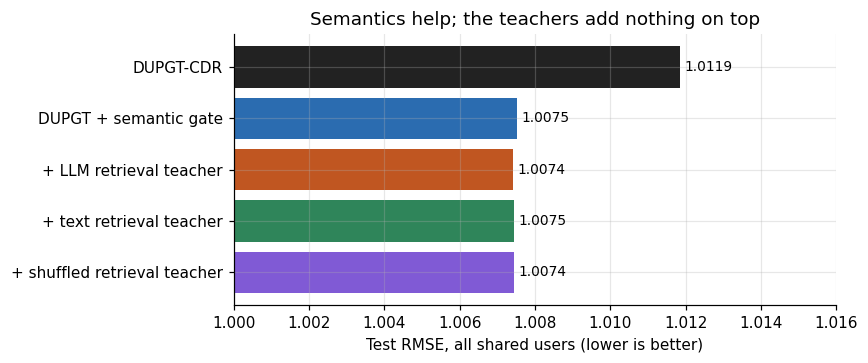

In [7]:
comparison = read(OUT / "amazon2023/semantic_transfer/full_seed2020/final_comparison/comparison.json")
def model_name(row):
    if row["teacher"] == "none":
        return "DUPGT-CDR" if row["model_variant"] == "dupgt" else "DUPGT + semantic gate"
    return {"retrieval_llm": "+ LLM retrieval teacher", "retrieval_text": "+ text retrieval teacher",
            "retrieval_shuffled": "+ shuffled retrieval teacher"}[row["teacher"]]
full = pd.DataFrame([{"Model": model_name(r), "MAE": r["mae"], "RMSE": r["rmse"]} for r in comparison["rows"]])
full = pd.concat([pd.DataFrame([{"Model": "Movie average", "MAE": comparison["rows"][0]["movie_mean_mae"],
                                 "RMSE": comparison["rows"][0]["movie_mean_rmse"]}]), full], ignore_index=True)
order = ["Movie average", "DUPGT-CDR", "DUPGT + semantic gate", "+ LLM retrieval teacher", "+ text retrieval teacher", "+ shuffled retrieval teacher"]
full = full.set_index("Model").loc[order].reset_index()
full["ΔRMSE vs DUPGT-CDR"] = full.RMSE - full.loc[full.Model == "DUPGT-CDR", "RMSE"].iloc[0]
display(full.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "ΔRMSE vs DUPGT-CDR": "{:+.4f}"}).hide(axis="index"))

fig, axis = plt.subplots(figsize=(8, 3.4))
part = full[full.Model != "Movie average"]
bars = axis.barh(part.Model, part.RMSE, color=[BLACK, BLUE, ORANGE, GREEN, PURPLE])
axis.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
axis.invert_yaxis(); axis.set_xlim(1.0, 1.016)
axis.set(xlabel="Test RMSE, all shared users (lower is better)", title="Semantics help; the teachers add nothing on top")
fig.tight_layout(); save(fig, "p03_semantic_full_overlap"); plt.show()

**What this shows**
* The **semantic gate lowers RMSE by about 0.0043** against DUPGT-CDR, with a similar gain in MAE.
* The three retrieval teachers differ from each other and from the gate alone by **at most 0.0001**. As in the pilot, the shuffled teacher matches the real one.
* With 89,031 shared users and about 1.5 million real ratings, 1,990 synthetic pairs are a drop in the ocean. The teacher could only matter where real data is scarce, which motivates the next section.

## 6. What happens when few users are shared?

This is the original research question. In practice, two platforms often share only a small fraction of their users. To simulate this, the bridge was trained on **1%, 10% and 100%** of the shared training users. The Book/Movie factor models and the test users stay exactly the same. The 1% and 10% levels were repeated with **three seeds**, where the seed decides which users form the subset and how the bridge starts. Within a seed, every model sees the same users and the same starting bridge, so model differences are *paired*.

In [8]:
ROOTS = [OUT / "amazon2023/overlap_seeds", OUT / "amazon2023/semantic_transfer/full_seed2020", OUT / "amazon2023/text_teacher_scale"]
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    rows = pd.DataFrame(collect(ROOTS, "test"))
runs = rows[rows.run != "baseline"]
summary, paired = map(pd.DataFrame, summarise(rows.to_dict("records")))
NAMES = {"movie_mean": "Movie average (no transfer)", "dupgt": "DUPGT-CDR", "semantics": "DUPGT + semantic gate",
         "semantics_llm_w0.01": "+ LLM teacher (λ=0.01)", "semantics_text_w0.01": "+ text teacher (λ=0.01)",
         "semantics_shuffled_w0.01": "+ shuffled teacher (λ=0.01)", "semantics_llm_w0.1": "+ LLM teacher (λ=0.1)",
         "semantics_text_w0.1": "+ text teacher (λ=0.1)", "semantics_shuffled_w0.1": "+ shuffled teacher (λ=0.1)",
         "semantics_text_only_w0.1": "+ text teacher, 1,988 users (λ=0.1)",
         "semantics_text_only_shuffled_w0.1": "+ shuffled text, 1,988 users (λ=0.1)"}
COLOUR = {"movie_mean": GREY, "dupgt": BLACK, "semantics": BLUE, "semantics_llm_w0.01": ORANGE,
          "semantics_text_w0.01": GREEN, "semantics_shuffled_w0.01": PURPLE, "semantics_llm_w0.1": ORANGE,
          "semantics_text_w0.1": GREEN, "semantics_shuffled_w0.1": PURPLE, "semantics_text_only_w0.1": GOLD,
          "semantics_text_only_shuffled_w0.1": "#a0aec0"}
design = rows.groupby("overlap_fraction").agg(users=("real_users", "first"), ratings=("real_ratings", "mean"),
                                              seeds=("seed", "nunique")).reset_index()
design.insert(0, "Shared users used", design.pop("overlap_fraction").map(lambda f: f"{f:.0%}"))
display(design.rename(columns={"users": "Users", "ratings": "Real Movie ratings", "seeds": "Seeds"})
        .style.format({"Users": "{:,}", "Real Movie ratings": "{:,.0f}"}).hide(axis="index"))

Shared users used,Users,Real Movie ratings,Seeds
1%,890,"14,851",3
10%,"8,903","149,383",3
100%,"89,031","1,497,886",1


### 6.1 Error against the amount of overlap

overlap,1%,10%,100%
Test RMSE (mean ± SD over seeds),,,
Movie average (no transfer),1.0507 ± 0.0000,1.0507 ± 0.0000,1.0507
DUPGT-CDR,1.1128 ± 0.0171,1.0301 ± 0.0012,1.0119
DUPGT + semantic gate,1.0926 ± 0.0168,1.0258 ± 0.0009,1.0075
+ LLM teacher (λ=0.01),1.0954 ± 0.0142,1.0259 ± 0.0010,1.0074
+ text teacher (λ=0.01),1.0955 ± 0.0142,1.0259 ± 0.0010,1.0075
+ shuffled teacher (λ=0.01),1.0953 ± 0.0143,1.0259 ± 0.0010,1.0074


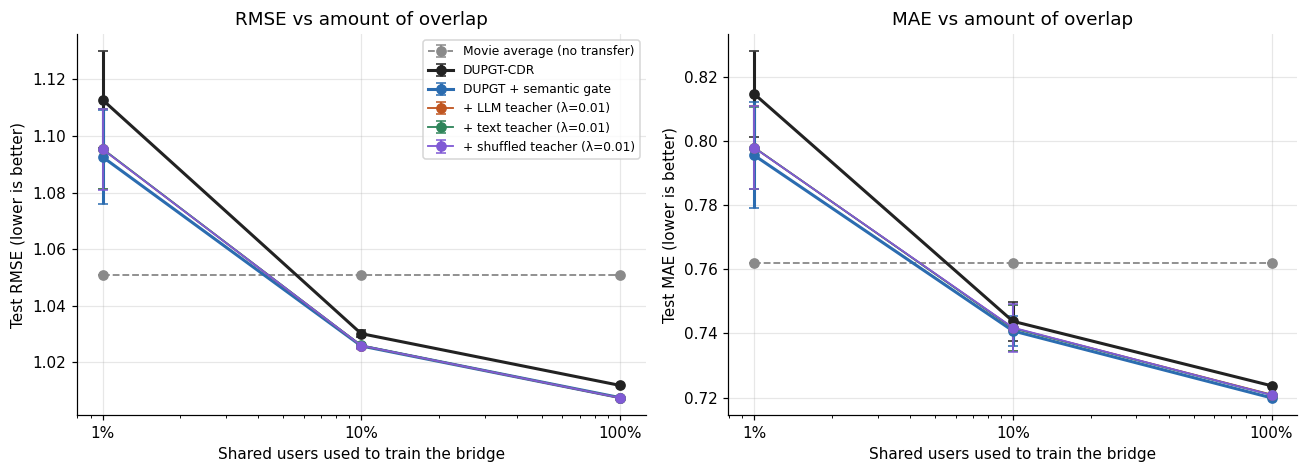

In [9]:
core = ["movie_mean", "dupgt", "semantics", "semantics_llm_w0.01", "semantics_text_w0.01", "semantics_shuffled_w0.01"]
def pm(mean, sd):
    return f"{mean:.4f}" if sd != sd else f"{mean:.4f} ± {sd:.4f}"
head = summary[summary.model.isin(core)].copy()
head["cell"] = [pm(m, s) for m, s in zip(head.rmse_mean, head.rmse_sd)]
head["overlap"] = head.overlap_fraction.map(lambda f: f"{f:.0%}")
table = head.pivot(index="model", columns="overlap", values="cell").loc[core][["1%", "10%", "100%"]]
table.index = table.index.map(NAMES)
display(table.rename_axis("Test RMSE (mean ± SD over seeds)"))

fractions = sorted(summary.overlap_fraction.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for axis, metric in zip(axes, ("rmse", "mae")):
    for model in core:
        part = summary[summary.model == model].sort_values("overlap_fraction")
        axis.errorbar(100 * part.overlap_fraction, part[f"{metric}_mean"], yerr=part[f"{metric}_sd"].fillna(0),
                      label=NAMES[model], color=COLOUR[model], marker="o", capsize=3,
                      linestyle="--" if model == "movie_mean" else "-", linewidth=2 if model in ("dupgt", "semantics") else 1.2)
    axis.set_xscale("log")
    axis.set_xticks([100 * f for f in fractions], [f"{f:.0%}" for f in fractions])
    axis.set(xlabel="Shared users used to train the bridge", ylabel=f"Test {metric.upper()} (lower is better)",
             title=f"{metric.upper()} vs amount of overlap")
axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "p04_overlap_curve"); plt.show()

**What this shows**
* With **1% of shared users (890 people)**, every transfer model is **worse than the movie average** (RMSE ≈ 1.09–1.11 vs 1.051), and results swing strongly with which users were sampled (SD ≈ 0.017).
* With **10% (8,903 people)**, transfer beats the movie average, and seed-to-seed variation almost disappears (SD ≈ 0.001). Error keeps falling up to 100%.
* So transfer only pays off somewhere **between about 900 and 9,000 shared users**. Below that, it does more harm than good.
* The teacher lines lie on top of the semantic-gate line at every overlap level.

### 6.2 Paired comparisons: which differences are real?

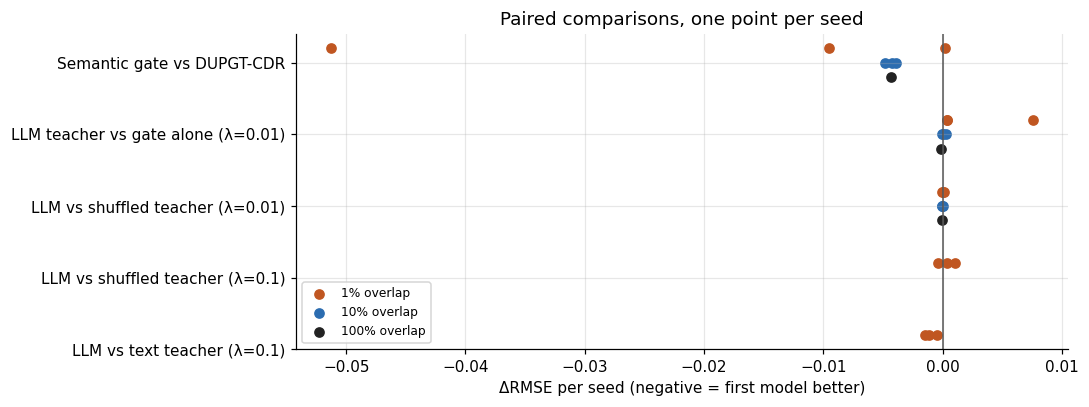

Comparison,Overlap,Seeds,Mean ΔRMSE,First model better in
Semantic gate vs DUPGT-CDR,1%,3,-0.02020,2/3
Semantic gate vs DUPGT-CDR,10%,3,-0.00435,3/3
Semantic gate vs DUPGT-CDR,100%,1,-0.00433,1/1
LLM teacher vs gate alone (λ=0.01),1%,3,+0.00277,0/3
LLM teacher vs gate alone (λ=0.01),10%,3,+0.00011,1/3
LLM teacher vs gate alone (λ=0.01),100%,1,-0.00010,1/1
LLM vs shuffled teacher (λ=0.01),1%,3,+0.00003,1/3
LLM vs shuffled teacher (λ=0.01),10%,3,-0.00001,2/3
LLM vs shuffled teacher (λ=0.01),100%,1,-0.00002,1/1
LLM vs shuffled teacher (λ=0.1),1%,3,+0.00034,1/3


In [10]:
lookup = rows.set_index(["overlap_fraction", "seed", "model"])["rmse"]
questions = [("semantics", "dupgt", "Semantic gate vs DUPGT-CDR"),
             ("semantics_llm_w0.01", "semantics", "LLM teacher vs gate alone (λ=0.01)"),
             ("semantics_llm_w0.01", "semantics_shuffled_w0.01", "LLM vs shuffled teacher (λ=0.01)"),
             ("semantics_llm_w0.1", "semantics_shuffled_w0.1", "LLM vs shuffled teacher (λ=0.1)"),
             ("semantics_llm_w0.1", "semantics_text_w0.1", "LLM vs text teacher (λ=0.1)")]
table_rows = []
fig, axis = plt.subplots(figsize=(10, 3.8))
for y, (model, reference, text) in enumerate(questions):
    for fraction, colour, offset in zip(fractions, (ORANGE, BLUE, BLACK), (-0.2, 0, 0.2)):
        values = [lookup[(fraction, s, model)] - lookup[(fraction, s, reference)] for s in sorted(rows.seed.unique())
                  if (fraction, s, model) in lookup.index and (fraction, s, reference) in lookup.index]
        if values:
            axis.scatter(values, [y + offset] * len(values), color=colour, s=36, label=f"{fraction:.0%} overlap" if y == 0 else None)
            table_rows.append({"Comparison": text, "Overlap": f"{fraction:.0%}", "Seeds": len(values),
                               "Mean ΔRMSE": np.mean(values), "First model better in": f"{sum(v < 0 for v in values)}/{len(values)}"})
axis.axvline(0, color="#555555", linewidth=1)
axis.set_yticks(range(len(questions)), [q[2] for q in questions]); axis.invert_yaxis()
axis.set(xlabel="ΔRMSE per seed (negative = first model better)", title="Paired comparisons, one point per seed")
axis.legend(fontsize=8, loc="lower left")
fig.tight_layout(); save(fig, "p05_paired_deltas"); plt.show()
display(pd.DataFrame(table_rows).style.format({"Mean ΔRMSE": "{:+.5f}"}).hide(axis="index"))

**What this shows**
* **The semantic gate is the only consistent gain.** At 10% it wins on all three seeds (≈ −0.0044 RMSE), and the gain is the same size at 100%. At 1% its average gain is larger but very noisy.
* **The LLM teacher never separates from its controls.** LLM vs shuffled stays within about ±0.001 at every overlap level and both weights. At λ = 0.1 the LLM is slightly better than the *text* teacher (3/3 seeds, −0.001), but no better than the shuffled one. The tiny effect is not personal.

### 6.3 Was the teacher simply too small?
At 1% overlap, real data is scarcest, so this is where a teacher should matter most. The text teacher needs no LLM, so it was scaled from 199 to **1,988 users (19,880 pairs, 10× more)**. Its first 200 users are exactly the LLM teacher's users. A shuffled version of the larger teacher serves as its control.

seed,2020,2021,2022,Mean,Δ vs gate alone
model,,,,,
DUPGT + semantic gate,1.1114,1.0870,1.0794,1.0926,+0.0000
+ LLM teacher (λ=0.1),1.1114,1.0842,1.0815,1.0924,-0.0002
+ text teacher (λ=0.1),1.1119,1.0853,1.0829,1.0934,+0.0008
+ shuffled teacher (λ=0.1),1.1118,1.0832,1.0811,1.0920,-0.0006
"+ text teacher, 1,988 users (λ=0.1)",1.1115,1.0846,1.0812,1.0925,-0.0001
"+ shuffled text, 1,988 users (λ=0.1)",1.1115,1.0847,1.0822,1.0928,+0.0002


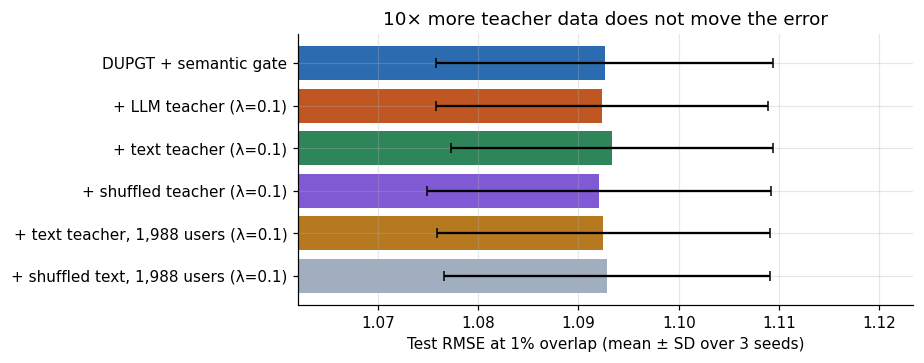

In [11]:
scale_models = ["semantics", "semantics_llm_w0.1", "semantics_text_w0.1", "semantics_shuffled_w0.1",
                "semantics_text_only_w0.1", "semantics_text_only_shuffled_w0.1"]
scale = rows[(rows.overlap_fraction == 0.01) & rows.model.isin(scale_models)]
per_seed = scale.pivot(index="model", columns="seed", values="rmse").loc[scale_models]
per_seed["Mean"] = per_seed.mean(axis=1)
per_seed["Δ vs gate alone"] = per_seed["Mean"] - per_seed.loc["semantics", "Mean"]
per_seed.index = per_seed.index.map(NAMES)
display(per_seed.style.format("{:.4f}").format("{:+.4f}", subset=["Δ vs gate alone"]))
means = scale.groupby("model").rmse.agg(["mean", "std"]).loc[scale_models]
fig, axis = plt.subplots(figsize=(8.5, 3.4))
axis.barh(range(len(means)), means["mean"], xerr=means["std"], color=[COLOUR[m] for m in means.index], capsize=3)
axis.set_yticks(range(len(means)), [NAMES[m] for m in means.index]); axis.invert_yaxis()
axis.set_xlim(means["mean"].min() - 0.03, means["mean"].max() + 0.03)
axis.set(xlabel="Test RMSE at 1% overlap (mean ± SD over 3 seeds)", title="10× more teacher data does not move the error")
fig.tight_layout(); save(fig, "p06_teacher_scale"); plt.show()

**What this shows.** Ten times more teacher pairs changes RMSE by about 0.0001 against the gate alone, and the larger teacher is not clearly better than its own shuffled control. The teacher's limit is *how* its signal is used, not how much of it there is.
* A pairwise "A over B" loss cannot change a user's overall rating level, and that level dominates RMSE.
* "Retrieved vs random" pairs mostly teach "relevant beats random", which any profile, including a shuffled one, teaches equally well.

### 6.4 Who is harmed by transfer?
The **negative transfer rate (NTR)** is the share of test users whose error is *worse* with transfer than with the movie average, computed from per-user MAE.

,1%,10%,100%
model,,,
DUPGT-CDR,56%,47%,42%
DUPGT + semantic gate,54%,47%,41%


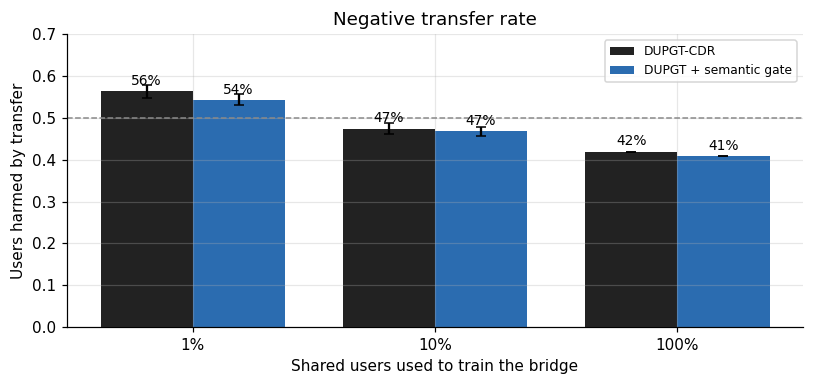

In [12]:
ntr_rows = []
for _, run in runs[runs.model.isin(["dupgt", "semantics"])].iterrows():
    users = pd.read_csv(Path(run.run) / "test_user_metrics.csv")
    worse = users.dupgt_minus_movie_mean_mae > 0
    ntr_rows.append({"overlap_fraction": run.overlap_fraction, "seed": run.seed, "model": run.model, "ntr": worse.mean()})
ntr = pd.DataFrame(ntr_rows).groupby(["overlap_fraction", "model"]).ntr.agg(["mean", "std"]).reset_index()
view = ntr.pivot(index="model", columns="overlap_fraction", values="mean").loc[["dupgt", "semantics"]]
view.columns = [f"{c:.0%}" for c in view.columns]; view.index = view.index.map(NAMES)
display(view.style.format("{:.0%}").set_caption("Share of test users worse off than with the movie average"))
fig, axis = plt.subplots(figsize=(7.5, 3.6))
for i, model in enumerate(["dupgt", "semantics"]):
    part = ntr[ntr.model == model].sort_values("overlap_fraction")
    x = np.arange(len(part)) + (i - 0.5) * 0.38
    axis.bar(x, part["mean"], 0.38, yerr=part["std"].fillna(0), color=COLOUR[model], label=NAMES[model], capsize=3)
    for xi, value in zip(x, part["mean"]):
        axis.text(xi, value + 0.015, f"{value:.0%}", ha="center", fontsize=9)
axis.axhline(0.5, color=GREY, linestyle="--", linewidth=1)
axis.set_xticks(range(len(fractions)), [f"{f:.0%}" for f in fractions])
axis.set(ylim=(0, 0.7), xlabel="Shared users used to train the bridge", ylabel="Users harmed by transfer",
         title="Negative transfer rate")
axis.legend(fontsize=8)
fig.tight_layout(); save(fig, "p07_negative_transfer_rate"); plt.show()

**What this shows.** NTR falls as overlap grows, from about **56% at 1% to about 41–42% at 100%**, but it never comes close to zero. Even in the best case, transfer makes roughly **4 in 10** users worse off. The semantic gate lowers it slightly at every level. DUPGT has no mechanism to recognise these users and fall back to the movie average for them.

### 6.5 Why does transfer fail at 1%? The gate collapses
DUPGT mixes its high-rating and low-rating bridges with the gate α_high. The saved test predictions record the gate for every rating.

Overlap,Seed,mean α_high,SD α_high,prediction SD
1%,2020,0.000,0.000,0.817
1%,2021,0.448,0.150,0.796
1%,2022,0.000,0.000,0.873
10%,2020,0.725,0.120,0.596
10%,2021,0.788,0.101,0.614
10%,2022,0.788,0.105,0.617
100%,2020,0.882,0.071,0.615


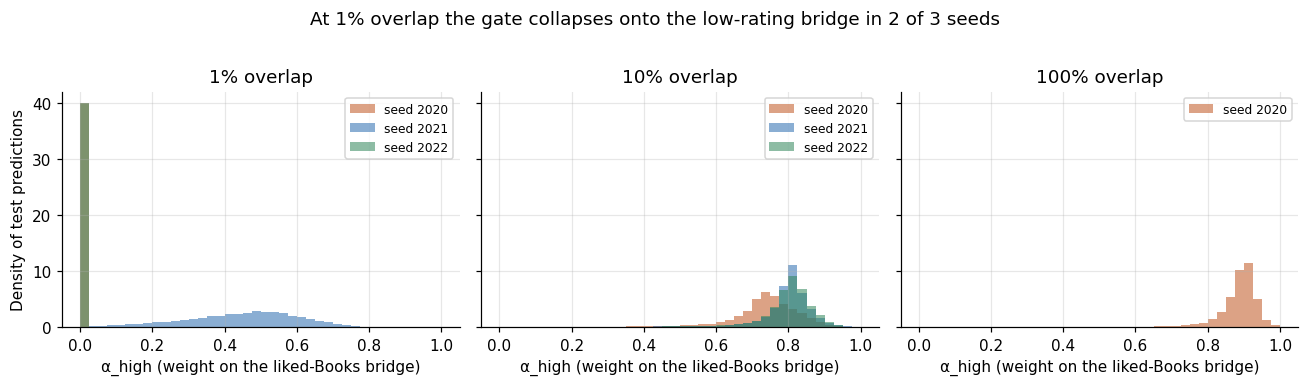

In [13]:
gate_samples, diag = {}, []
for _, run in runs[runs.model.isin(["dupgt", "semantics"])].iterrows():
    p = pd.read_csv(Path(run.run) / "test_predictions.csv.gz", usecols=["actual_rating", "dupgt", "alpha_high"])
    diag.append({"overlap_fraction": run.overlap_fraction, "seed": run.seed, "model": run.model,
                 "mean α_high": p.alpha_high.mean(), "SD α_high": p.alpha_high.std(), "prediction SD": p.dupgt.std()})
    if run.model == "dupgt":
        gate_samples[(run.overlap_fraction, run.seed)] = p.alpha_high.sample(20000, random_state=0).to_numpy()
diag = pd.DataFrame(diag)
gate_view = diag[diag.model == "dupgt"].assign(Overlap=lambda d: d.overlap_fraction.map(lambda f: f"{f:.0%}"))
display(gate_view[["Overlap", "seed", "mean α_high", "SD α_high", "prediction SD"]].rename(columns={"seed": "Seed"})
        .style.format({"mean α_high": "{:.3f}", "SD α_high": "{:.3f}", "prediction SD": "{:.3f}"}).hide(axis="index"))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for axis, fraction in zip(axes, fractions):
    for seed, shade in zip(sorted(rows.seed.unique()), (ORANGE, BLUE, GREEN)):
        if (fraction, seed) in gate_samples:
            axis.hist(gate_samples[(fraction, seed)], bins=np.linspace(0, 1, 41), alpha=0.55, color=shade, label=f"seed {seed}", density=True)
    axis.set(title=f"{fraction:.0%} overlap", xlabel="α_high (weight on the liked-Books bridge)")
    axis.legend(fontsize=8)
axes[0].set_ylabel("Density of test predictions")
fig.suptitle("At 1% overlap the gate collapses onto the low-rating bridge in 2 of 3 seeds", y=1.02)
fig.tight_layout(); save(fig, "p08_gate_collapse"); plt.show()

**What this shows**
* At **1%**, in two of three seeds, α_high is essentially **0 for every prediction**. The gate has collapsed: every user goes through the low-rating bridge, so the high/low split that defines DUPGT is switched off. The seed that did not collapse also has the lowest error.
* At 1%, predictions are also **over-dispersed**: their spread (SD ≈ 0.80–0.87) is far wider than at 10% or 100% (≈ 0.60–0.62). With little data, the bridge is over-confident, and that pushes RMSE above the movie average.
* At 10% and 100%, the gate is healthy: it leans towards the liked-Books bridge (mean ≈ 0.73–0.88) with real variation across users.

### 6.6 Which users benefit? Error by size of Book history (all shared users)

,Test ratings,Movie average RMSE,DUPGT-CDR RMSE,Gain from transfer
Book ratings in history,,,,
5–7,"127,286",1.0646,1.0501,+0.0145
8–12,"106,112",1.0525,1.0118,+0.0406
13–25,"95,800",1.0213,0.9787,+0.0426
26+,"104,420",1.0584,0.9942,+0.0643


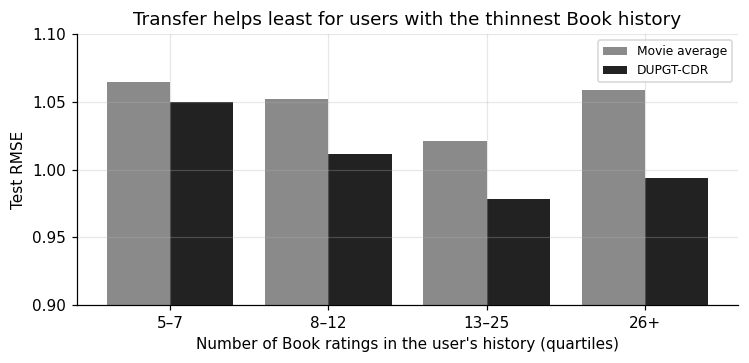

In [14]:
full_run = runs[(runs.overlap_fraction == 1.0) & (runs.model == "dupgt")].iloc[0]
p = pd.read_csv(Path(full_run.run) / "test_predictions.csv.gz",
                usecols=["actual_rating", "movie_mean", "dupgt", "source_high_count", "source_low_count"])
p["books"] = p.source_high_count + p.source_low_count
edges = np.quantile(p.books, [0, .25, .5, .75, 1]).astype(int)
labels = [f"{edges[0]}–{edges[1]}"] + [f"{a + 1}–{b}" for a, b in zip(edges[1:-2], edges[2:-1])] + [f"{edges[-2] + 1}+"]
p["Book ratings in history"] = pd.cut(p.books, [-1, *edges[1:-1], np.inf], labels=labels)
by_history = p.groupby("Book ratings in history", observed=True).apply(lambda g: pd.Series({
    "Test ratings": len(g), "Movie average RMSE": np.sqrt(((g.movie_mean - g.actual_rating) ** 2).mean()),
    "DUPGT-CDR RMSE": np.sqrt(((g.dupgt - g.actual_rating) ** 2).mean())}))
by_history["Gain from transfer"] = by_history["Movie average RMSE"] - by_history["DUPGT-CDR RMSE"]
display(by_history.style.format({"Test ratings": "{:,.0f}", "Movie average RMSE": "{:.4f}", "DUPGT-CDR RMSE": "{:.4f}",
                                  "Gain from transfer": "{:+.4f}"}))
fig, axis = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(by_history))
axis.bar(x - 0.2, by_history["Movie average RMSE"], 0.4, color=GREY, label="Movie average")
axis.bar(x + 0.2, by_history["DUPGT-CDR RMSE"], 0.4, color=BLACK, label="DUPGT-CDR")
axis.set_xticks(x, by_history.index.astype(str)); axis.set_ylim(0.9, 1.1)
axis.set(xlabel="Number of Book ratings in the user's history (quartiles)", ylabel="Test RMSE",
         title="Transfer helps least for users with the thinnest Book history")
axis.legend(fontsize=8)
fig.tight_layout(); save(fig, "p09_error_by_history"); plt.show()

**What this shows.** Users with only 5–7 Book ratings gain about **0.015** RMSE from transfer. Users with richer histories gain **0.04–0.06**. Transfer is least useful exactly where a cold-start system needs it most.

## 7. Third extension: knowing when not to transfer

Section 6 showed that DUPGT always trusts its bridge, even when the bridge is unreliable. The idea here is a **fallback**: for each user and movie, estimate how uncertain the bridge's prediction is, and move the prediction towards the movie average by that amount. This is **inverse-variance weighting**, the same rule used to combine two noisy measurements:

$$\hat r = w\,\mu + (1-w)\,\bar r_{\text{movie}}, \qquad w = \frac{s_0}{s_0 + \sigma^2}$$

Here μ is the bridge's prediction, σ² is its estimated error variance, and s₀ is the variance of ratings around the movie average. A confident bridge (small σ²) keeps w close to 1. An unreliable one is pulled back to the movie average. Two ways of estimating σ² were tested.

**A. Ensemble disagreement.** Five bridges are trained per seed, differing only in their random start. Their mean is μ and their standard deviation *d* measures disagreement. Then σ² = τ² + c·d², where τ² and c are fitted on **validation data only**. A **constant blend** (c = 0, the same shrinkage for every prediction) is the control: if the uncertainty blend only matches it, disagreement adds nothing beyond plain shrinkage.

**B. Probabilistic bridge.** A single semantic-gate bridge with an extra **variance head** that outputs log σ² for every prediction. It is trained with three terms: the usual squared error on μ, a Gaussian negative log-likelihood for σ² (with μ held fixed, so the variance cannot distort the prediction), and the squared error of the blended prediction, which fits s₀. An optional **gate prior** with weight λ gently pulls the gate's log-odds z towards 0 using λ·(√(1+z²) − 1). It targets the gate collapse found in section 6.5. λ = 0 turns it off.

Both methods are *added* to the existing code. Previous runs, checkpoints and the lock → evaluate workflow are unchanged, and both blends were fitted and locked before any test scoring.

In [15]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    low = pd.DataFrame(collect([OUT / "amazon2023/overlap_seeds", OUT / "amazon2023/probabilistic_bridge"], "test"))
low = low[low.overlap_fraction < 1]
low["negative_transfer_rate"] = [np.nan if r == "baseline" else
                                 (pd.read_csv(Path(r) / "test_user_metrics.csv").dupgt_minus_movie_mean_mae > 0).mean()
                                 for r in low.run]
ens = []
for f in sorted((OUT / "amazon2023/uncertainty_ensemble").glob("overlap_*/seed_*/blend/test_metrics.json")):
    m, b = read(f), read(f.with_name("blend.json"))
    fraction, seed = float(f.parts[-4].split("_")[1]), int(f.parts[-3].split("_")[1])
    single = pd.DataFrame(m["single_bridges"]).mean()
    for key, values in [("one_bridge", single), ("ensemble_mean", m["ensemble_mean"]),
                        ("constant_blend", m["constant_blend"]), ("uncertainty_blend", m["uncertainty_blend"])]:
        ens.append({"overlap_fraction": fraction, "seed": seed, "model": key, "rmse": values["rmse"], "mae": values["mae"],
                    "ntr": values["negative_transfer_rate"]})
ens = pd.DataFrame(ens)
base = low[low.model.isin(["movie_mean", "dupgt", "semantics", "probabilistic_g0", "probabilistic_g0.1"])]
both = pd.concat([base[["overlap_fraction", "seed", "model", "rmse", "mae", "negative_transfer_rate"]]
                  .rename(columns={"negative_transfer_rate": "ntr"}), ens], ignore_index=True)
ORDER7 = ["movie_mean", "dupgt", "semantics", "one_bridge", "ensemble_mean", "probabilistic_g0", "probabilistic_g0.1",
          "constant_blend", "uncertainty_blend"]
NAMES7 = {**NAMES, "one_bridge": "One semantic bridge (avg of the 5)", "ensemble_mean": "A. Ensemble of 5 bridges (no fallback)",
          "probabilistic_g0": "B. Probabilistic bridge (λ=0)", "probabilistic_g0.1": "B. Probabilistic bridge + gate prior (λ=0.1)",
          "constant_blend": "A. Ensemble + constant blend (control)", "uncertainty_blend": "A. Ensemble + uncertainty blend"}
stats = both.groupby(["model", "overlap_fraction"]).agg(rmse=("rmse", "mean"), sd=("rmse", "std"), mae=("mae", "mean"),
                                                        ntr=("ntr", "mean")).reset_index()
cell = lambda r: pm(r.rmse, r.sd) if r.model != "movie_mean" else f"{r.rmse:.4f}"
stats["RMSE"] = stats.apply(cell, axis=1)
stats["overlap"] = stats.overlap_fraction.map(lambda f: f"{f:.0%}")
wide = stats.pivot(index="model", columns="overlap", values=["RMSE", "mae", "ntr"]).loc[ORDER7]
table7 = pd.DataFrame({"RMSE 1%": wide["RMSE"]["1%"], "RMSE 10%": wide["RMSE"]["10%"],
                       "MAE 1%": wide["mae"]["1%"].astype(float).round(4), "MAE 10%": wide["mae"]["10%"].astype(float).round(4),
                       "Users harmed 1%": wide["ntr"]["1%"].astype(float).map(lambda v: "—" if v != v else f"{v:.1%}"),
                       "Users harmed 10%": wide["ntr"]["10%"].astype(float).map(lambda v: "—" if v != v else f"{v:.1%}")})
table7.index = table7.index.map(NAMES7)
display(table7.rename_axis("Test error, mean ± SD over 3 seeds"))

,RMSE 1%,RMSE 10%,MAE 1%,MAE 10%,Users harmed 1%,Users harmed 10%
"Test error, mean ± SD over 3 seeds",,,,,,
Movie average (no transfer),1.0507,1.0507,0.7620,0.7620,—,—
DUPGT-CDR,1.1128 ± 0.0171,1.0301 ± 0.0012,0.8146,0.7438,56.3%,47.4%
DUPGT + semantic gate,1.0926 ± 0.0168,1.0258 ± 0.0009,0.7954,0.7408,54.3%,46.8%
One semantic bridge (avg of the 5),1.0830 ± 0.0125,1.0311 ± 0.0079,0.7883,0.7423,53.4%,46.3%
A. Ensemble of 5 bridges (no fallback),1.0678 ± 0.0078,1.0244 ± 0.0014,0.7758,0.7366,51.3%,45.4%
B. Probabilistic bridge (λ=0),1.0246 ± 0.0013,1.0128 ± 0.0011,0.7382,0.7308,42.7%,44.3%
B. Probabilistic bridge + gate prior (λ=0.1),1.0231 ± 0.0026,1.0122 ± 0.0006,0.7387,0.7402,43.0%,47.4%
A. Ensemble + constant blend (control),1.0211 ± 0.0010,1.0104 ± 0.0007,0.7428,0.7341,43.5%,42.6%
A. Ensemble + uncertainty blend,1.0202 ± 0.0014,1.0097 ± 0.0004,0.7404,0.7328,43.5%,42.5%


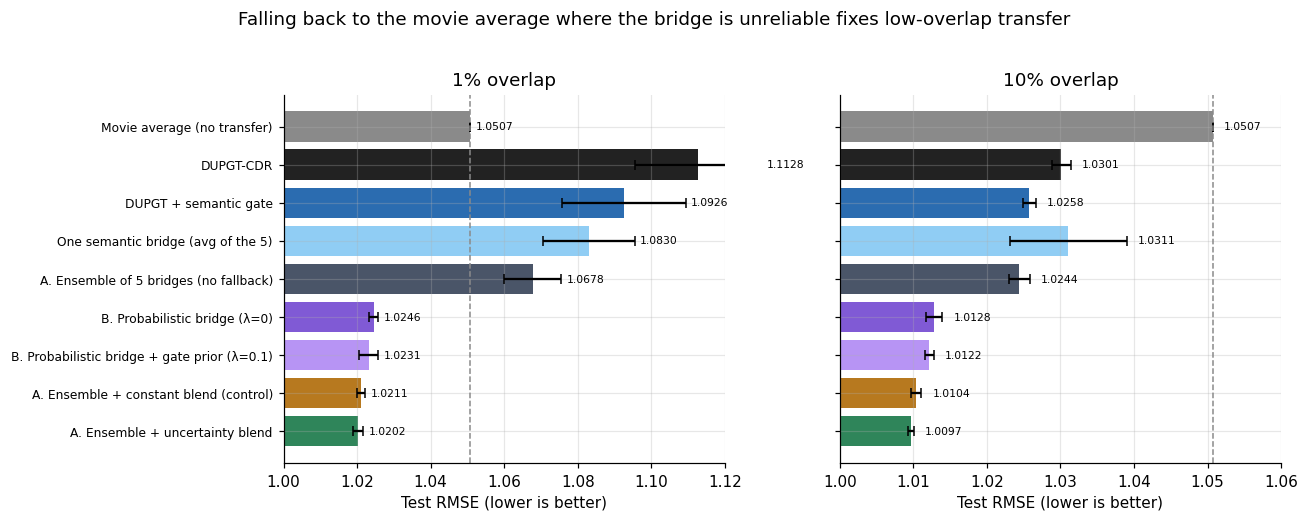

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=False)
COLOUR7 = {"movie_mean": GREY, "dupgt": BLACK, "semantics": BLUE, "one_bridge": "#90cdf4", "ensemble_mean": "#4a5568",
           "probabilistic_g0": PURPLE, "probabilistic_g0.1": "#b794f4", "constant_blend": GOLD, "uncertainty_blend": GREEN}
for axis, fraction in zip(axes, (0.01, 0.10)):
    part = stats[stats.overlap_fraction == fraction].set_index("model").loc[ORDER7]
    y = np.arange(len(part))[::-1]
    axis.barh(y, part.rmse, xerr=part.sd.fillna(0), color=[COLOUR7[m] for m in part.index], capsize=3)
    axis.axvline(part.loc["movie_mean", "rmse"], color=GREY, linestyle="--", linewidth=1)
    axis.set_yticks(y, [NAMES7[m] for m in part.index], fontsize=8)
    axis.set_xlim(1.0, 1.12 if fraction == 0.01 else 1.06)
    axis.set(xlabel="Test RMSE (lower is better)", title=f"{fraction:.0%} overlap")
    for yy, value, sd in zip(y, part.rmse, part.sd.fillna(0)):
        axis.text(value + sd + 0.0015, yy, f"{value:.4f}", va="center", fontsize=7)
axes[1].set_yticklabels([])
fig.suptitle("Falling back to the movie average where the bridge is unreliable fixes low-overlap transfer", y=1.02)
fig.tight_layout(); save(fig, "p10_fallback_results"); plt.show()

**What this shows**
* **At 1% overlap, transfer finally beats the movie average.** Every model without a fallback is 0.02–0.06 *worse* than the movie average. Both fallback methods are about **0.03 better**, on every seed, and the seed-to-seed spread drops from about 0.017 to about 0.001.
* **At 10% overlap, the uncertainty blend reaches 1.0097**, lower than DUPGT-CDR trained on **all** shared users (1.0119, section 6). The share of harmed users falls from about 47% to about 42.5%.
* **Averaging bridges alone is not enough.** The ensemble mean improves on a single bridge but still loses to the movie average at 1%. The gain comes from the fallback.
* The probabilistic bridge gets close to the ensemble blend (within about 0.002–0.003) with **one model instead of five**.

### 7.1 Is it just shrinkage? Uncertainty blend against the constant-blend control

In [17]:
pair = ens.pivot_table(index=["overlap_fraction", "seed"], columns="model", values=["rmse", "mae"])
paired7 = pd.DataFrame({"Constant blend RMSE": pair["rmse"]["constant_blend"], "Uncertainty blend RMSE": pair["rmse"]["uncertainty_blend"],
                        "Δ RMSE": pair["rmse"]["uncertainty_blend"] - pair["rmse"]["constant_blend"],
                        "Δ MAE": pair["mae"]["uncertainty_blend"] - pair["mae"]["constant_blend"]}).reset_index()
paired7.insert(0, "Overlap", paired7.pop("overlap_fraction").map(lambda f: f"{f:.0%}"))
display(fmt(paired7.rename(columns={"seed": "Seed"}), **{"Δ RMSE": "{:+.4f}", "Δ MAE": "{:+.4f}"}))
fits = []
for f in sorted((OUT / "amazon2023/uncertainty_ensemble").glob("overlap_*/seed_*/blend/blend.json")):
    b = read(f)
    s0, t, c = b["uncertainty_blend"]["s0"], b["uncertainty_blend"]["tau2"], b["uncertainty_blend"]["c"]
    fits.append({"Overlap": f"{float(f.parts[-4].split('_')[1]):.0%}", "Seed": int(f.parts[-3].split("_")[1]),
                 "constant weight w": s0 / (s0 + b["constant_blend"]["tau2"]), "τ²": t, "c": c})
display(fmt(pd.DataFrame(fits), 3))

Overlap,Seed,Constant blend RMSE,Uncertainty blend RMSE,Δ RMSE,Δ MAE
1%,2020,1.0217,1.0212,-0.0005,-0.0018
1%,2021,1.0199,1.0187,-0.0012,-0.0035
1%,2022,1.0216,1.0207,-0.0010,-0.0020
10%,2020,1.0106,1.0096,-0.0010,-0.0019
10%,2021,1.0095,1.0094,-0.0002,-0.0003
10%,2022,1.0109,1.0101,-0.0009,-0.0016


Overlap,Seed,constant weight w,τ²,c
1%,2020,0.403,1.259,2.512
1%,2021,0.460,0.794,10.000
1%,2022,0.460,1.000,10.000
10%,2020,0.629,0.501,12.589
10%,2021,0.629,0.631,0.794
10%,2022,0.629,0.501,10.000


**What this shows**
* The uncertainty blend beats the constant blend on **all 6 seed groups**, but only by about **0.001 RMSE** (and about 0.002 MAE). The sign never flips, so the effect is real. It is small.
* **Most of the gain is plain shrinkage.** The fitted constant weight is about 0.4–0.5 at 1% and about 0.6 at 10%: with few shared users, the best single rule is to trust the bridge only about half way.
* The fitted c is positive on every seed (about 0.8–12.6), so disagreement *is* used: predictions on which the bridges disagree are pulled back harder. The next figure shows why.

,Ensemble MAE − movie-average MAE,Mean weight on the bridge
Disagreement quintile,,
1 (agree),-0.0565,0.678
2,-0.0472,0.673
3,-0.0345,0.667
4,-0.0167,0.655
5 (disagree),+0.0263,0.591


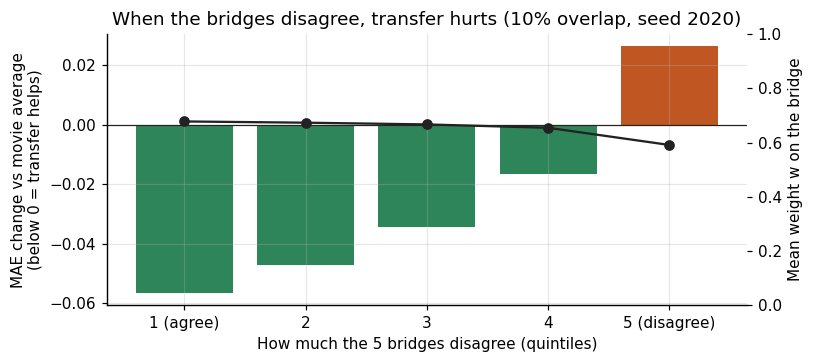

In [18]:
p = pd.read_csv(OUT / "amazon2023/uncertainty_ensemble/overlap_0.10/seed_2020/blend/test_predictions.csv.gz")
p["Disagreement quintile"] = pd.qcut(p.disagreement, 5, labels=["1 (agree)", "2", "3", "4", "5 (disagree)"])
quint = p.groupby("Disagreement quintile", observed=True).apply(lambda g: pd.Series({
    "Ensemble MAE − movie-average MAE": (abs(g.ensemble_mean - g.actual_rating) - abs(g.movie_mean - g.actual_rating)).mean(),
    "Mean weight on the bridge": g.weight.mean()}))
display(quint.style.format("{:+.4f}", subset=["Ensemble MAE − movie-average MAE"]).format("{:.3f}", subset=["Mean weight on the bridge"]))
fig, axis = plt.subplots(figsize=(7.5, 3.4))
gain = quint["Ensemble MAE − movie-average MAE"]
axis.bar(range(5), gain, color=[GREEN if v < 0 else ORANGE for v in gain])
axis.axhline(0, color=BLACK, linewidth=0.8)
axis.set_xticks(range(5), quint.index.astype(str))
axis.set(xlabel="How much the 5 bridges disagree (quintiles)", ylabel="MAE change vs movie average\n(below 0 = transfer helps)",
         title="When the bridges disagree, transfer hurts (10% overlap, seed 2020)")
twin = axis.twinx(); twin.plot(range(5), quint["Mean weight on the bridge"], color=BLACK, marker="o")
twin.set_ylabel("Mean weight w on the bridge"); twin.set_ylim(0, 1); twin.grid(False)
fig.tight_layout(); save(fig, "p11_disagreement_vs_harm"); plt.show()

**What this shows.** Where the bridges agree, transfer clearly beats the movie average. Where they disagree most, transfer is *worse* than the movie average. The blend weight falls in step (from about 0.68 to 0.59), so the fallback pulls back hardest exactly where transfer hurts. Disagreement is therefore a genuine signal of harm. But the weight changes only modestly between quintiles: most of the correction is the same for every prediction, which is why the constant blend already captures most of the benefit.

### 7.2 The probabilistic bridge and the gate prior

In [19]:
gate7 = []
for _, run in low[low.model.isin(["semantics", "probabilistic_g0", "probabilistic_g0.1"])].iterrows():
    a = pd.read_csv(Path(run.run) / "test_predictions.csv.gz", usecols=["alpha_high"]).alpha_high
    gate7.append({"Overlap": f"{run.overlap_fraction:.0%}", "Seed": run.seed, "Model": NAMES7[run.model],
                  "mean α_high": a.mean(), "RMSE": run.rmse, "MAE": run.mae, "Users harmed": run.negative_transfer_rate})
gate7 = pd.DataFrame(gate7).sort_values(["Overlap", "Seed", "Model"])
display(fmt(gate7, 4, **{"mean α_high": "{:.3f}", "Users harmed": "{:.1%}"}))

Overlap,Seed,Model,mean α_high,RMSE,MAE,Users harmed
1%,2020,B. Probabilistic bridge (λ=0),0.000,1.0253,0.7450,45.1%
1%,2020,B. Probabilistic bridge + gate prior (λ=0.1),0.458,1.0259,0.7307,38.4%
1%,2020,DUPGT + semantic gate,0.000,1.1114,0.8135,55.7%
1%,2021,B. Probabilistic bridge (λ=0),0.100,1.0231,0.7421,44.6%
1%,2021,B. Probabilistic bridge + gate prior (λ=0.1),0.487,1.0207,0.7407,44.5%
1%,2021,DUPGT + semantic gate,0.124,1.0870,0.7916,54.2%
1%,2022,B. Probabilistic bridge (λ=0),0.002,1.0253,0.7276,38.4%
1%,2022,B. Probabilistic bridge + gate prior (λ=0.1),0.506,1.0228,0.7446,46.2%
1%,2022,DUPGT + semantic gate,0.117,1.0794,0.7813,53.1%
10%,2020,B. Probabilistic bridge (λ=0),0.702,1.0137,0.7246,42.5%


**What this shows**
* **The variance head does the main work.** With the gate prior off (λ = 0), the probabilistic bridge is already about 0.068 better than the semantic gate at 1% and 0.013 better at 10%, on every seed.
* **The gate prior fixes the collapse.** At 1%, α_high stays around 0.46–0.51 instead of falling to 0, and RMSE improves slightly (−0.0014, 2 of 3 seeds).
* **It over-regularises when data is plentiful.** At 10% the gate was already healthy (about 0.8). The prior pulls it towards 0.5. RMSE barely changes (−0.0007), but MAE gets worse (+0.009). λ = 0.1 is too strong once there is enough overlap.
* A constant blend of the five-bridge ensemble already beats the probabilistic bridge. Its gain is therefore also mostly shrinkage. Its advantages are needing one model instead of five, and fixing the gate collapse.

## 8. Conclusions

1. **Baseline.** DUPGT-CDR reproduces on both Amazon releases. It beats global-mean, movie-average and linear-mapping baselines, with RMSE about 3–4% below the movie average.
2. **LLM supervision.** Neither design (pairwise preferences or retrieved interests) produces a measurable gain. Every teacher ties a shuffled control that contains no personal information, at every overlap level and teacher weight. Ten times more teacher data does not change this. Directly checked, the LLM's preference calls are less accurate than text similarity or popularity.
3. **Semantics.** Reading Book and Movie descriptions through a semantic gate gives a small but consistent gain (about −0.0044 RMSE at 10% and 100% overlap, on every seed).
4. **Limited overlap.** Transfer needs enough shared users. With 1% (890 users), every transfer model is worse than the movie average. The break-even lies between about 900 and 9,000 shared users.
5. **Mechanism.** At low overlap, DUPGT's high/low gate collapses onto one branch and its predictions become over-dispersed.
6. **Negative transfer.** Even with all shared users, about 4 in 10 test users are harmed by transfer. Users with short Book histories gain the least. DUPGT always transfers; it has no way to tell when its own bridge is unreliable.
7. **Fallback.** Moving each prediction towards the movie average by inverse-variance weighting fixes low overlap. At 1%, transfer becomes about **0.03 better than the movie average** on every seed, instead of 0.04–0.06 worse. At 10%, the five-bridge uncertainty blend (1.0097) beats DUPGT trained on all shared users (1.0119). A single probabilistic bridge gets within about 0.002–0.003 of it.
8. **Shrinkage vs uncertainty.** Most of that gain is plain shrinkage: a constant blend gets nearly all of it. Ensemble disagreement adds a small but consistent extra (about −0.001 RMSE on 6 of 6 seed groups). The bridges disagree most exactly where transfer hurts.

### Why the teachers could not help
* **Too small.** 1,990–19,880 synthetic pairs, against tens of thousands to 1.5 million real ratings.
* **Wrong target.** A pairwise loss only says "A over B". It cannot fix a user's overall rating level, which dominates RMSE.
* **Too easy.** "Retrieved vs random" pairs mostly teach "relevant beats random", which any profile teaches.
* **Weak labels.** The LLM is right on 46% of checked pairs, below a coin flip and below simple heuristics.

### Limitations
* The 100%-overlap results come from a single seed. The 1% and 10% results use three seeds.
* The 2023 test split was examined during earlier stages. The limited-overlap results are therefore follow-up evidence, not a pristine hold-out.
* As in DUPGT, a 3★ rating is grouped with "low". Book histories are taken in file order rather than by time.
* Only one source→target pair (Books → Movies & TV) was studied.

* Negative transfer is measured per user, on a median of about 9 test ratings. Part of the ~42% is measurement noise: even if every user gained equally, noise alone would make about a third look harmed.
* The uncertainty weights are fitted on validation data per seed. The ensemble needs five trained bridges.

### What remains open
The fallback answers *how much* to trust the bridge, but it mostly does so uniformly. A sharper signal of **which** users will be harmed, beyond ensemble disagreement, would be needed to push negative transfer well below 40%. A gate prior that adapts its strength to the amount of overlap would keep the 1% fix without over-regularising at 10%.